#### Análisis y Procesamiento de Señales

# TS1: Síntesis y operaciones de señales
#### Juan Martucci


# Análisis Y Resultados

## Ejercicio 1:


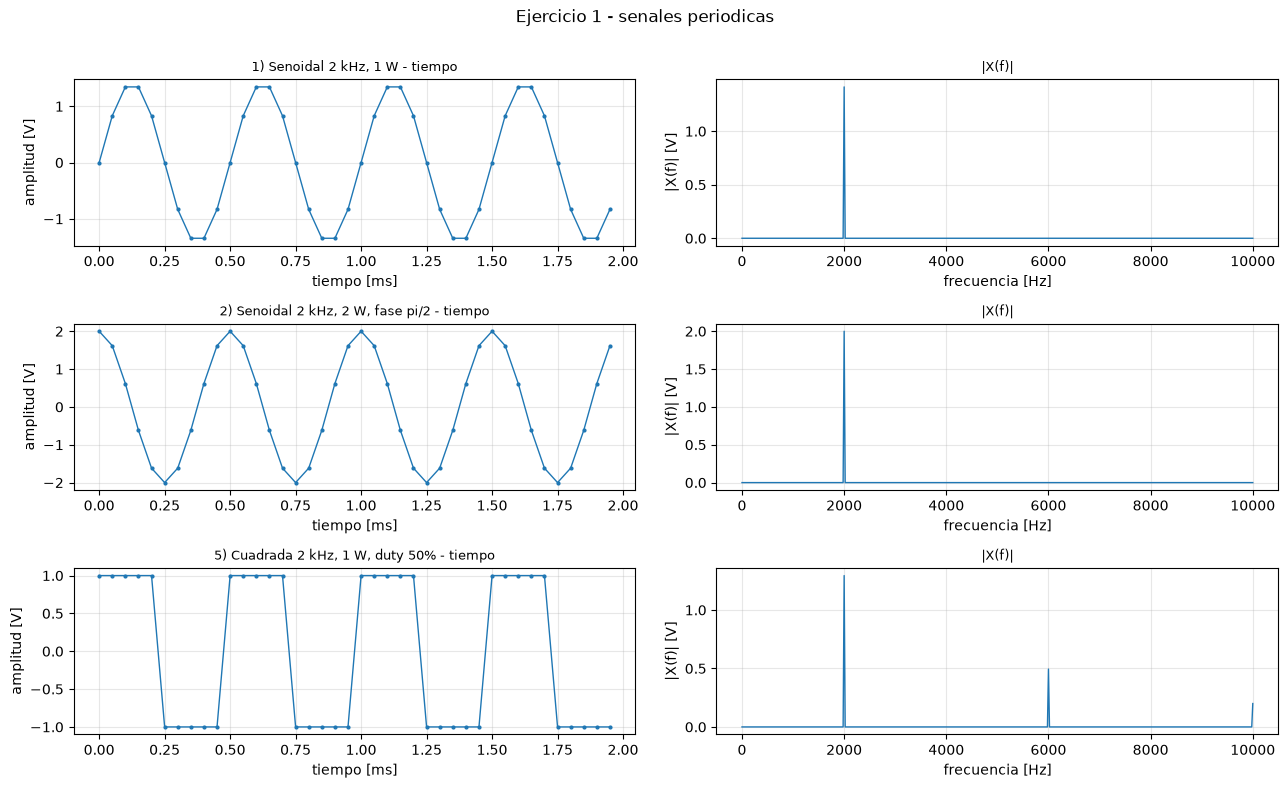

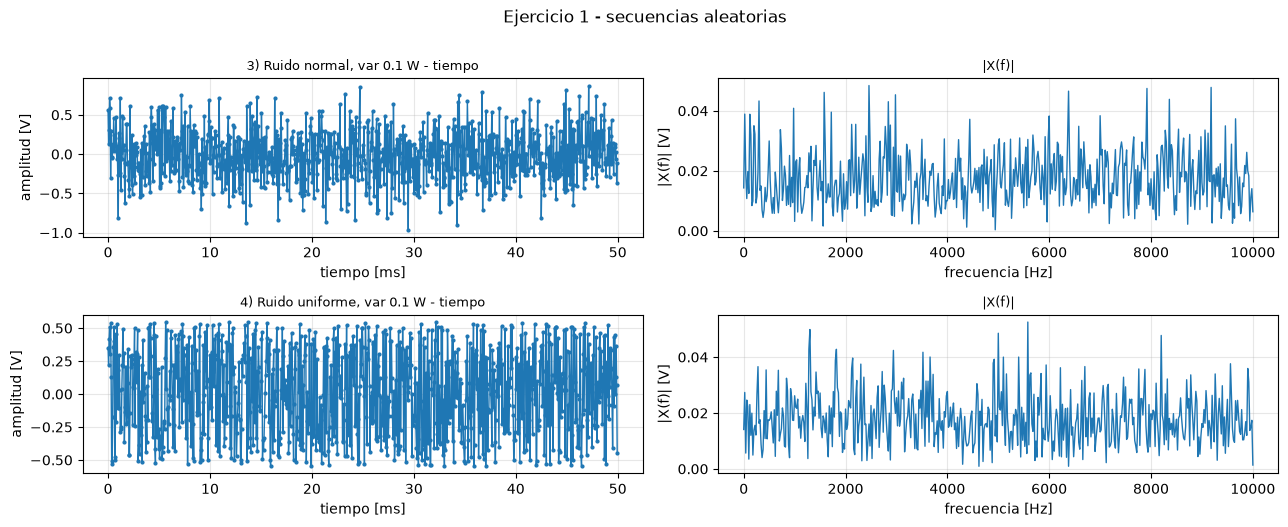

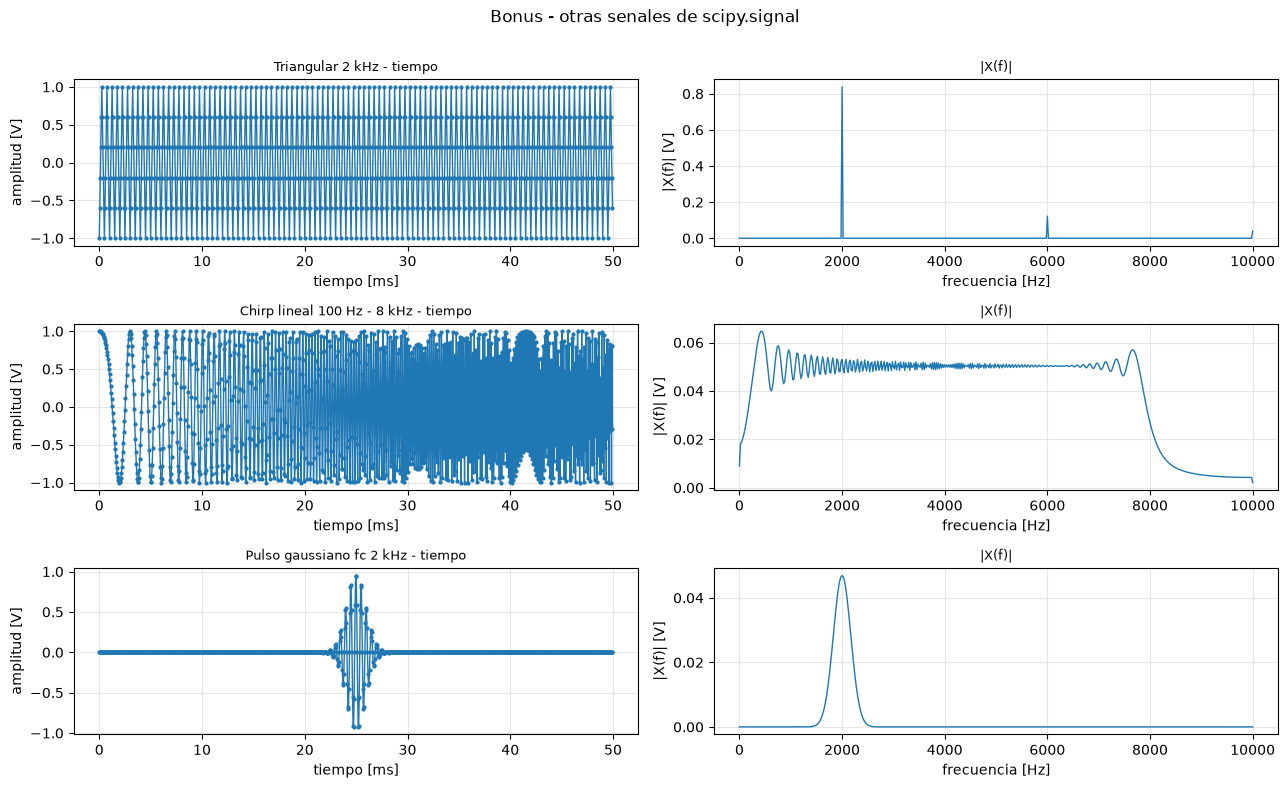

senal                                 media    P tiempo   P Parseval
--------------------------------------------------------------------
1) Senoidal 2 kHz, 1 W                 0.0000     1.0000       1.0000
2) Senoidal 2 kHz, 2 W, fase pi/2     -0.0000     2.0000       2.0000
3) Ruido normal, var 0.1 W            -0.0143     0.0976       0.0976
4) Ruido uniforme, var 0.1 W           0.0141     0.1026       0.1026
5) Cuadrada 2 kHz, 1 W, duty 50%       0.0000     1.0000       1.0000
Triangular 2 kHz                       0.0000     0.3600       0.3600
Chirp lineal 100 Hz - 8 kHz            0.0089     0.5024       0.5024
Pulso gaussiano fc 2 kHz               0.0000     0.0166       0.0166


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal as sig

np.random.seed(0)

# Parametros
N  = 1000
fs = 20000.0          
f0 = 2000.0
df = fs / N
t  = np.arange(N) / fs
f  = np.arange(N//2 + 1) * df


fase = 2*np.pi*np.mod(f0*t, 1.0)  # Envuelvo la fase a [0,2pi) para que sig.square no pierda precision en los flancos.

senales = {
    "1) Senoidal 2 kHz, 1 W"            : np.sqrt(2) * np.sin(fase),
    "2) Senoidal 2 kHz, 2 W, fase pi/2" : 2 * np.sin(fase + np.pi/2),
    "3) Ruido normal, var 0.1 W"        : np.random.normal(0.0, np.sqrt(0.1), N),
    "4) Ruido uniforme, var 0.1 W"      : np.random.uniform(-np.sqrt(0.3), np.sqrt(0.3), N),
    "5) Cuadrada 2 kHz, 1 W, duty 50%"  : sig.square(fase, duty=0.5),
}

# Bonus: otras senales de scipy.signal
bonus = {
    "Triangular 2 kHz"            : sig.sawtooth(fase, width=0.5),
    "Chirp lineal 100 Hz - 8 kHz" : sig.chirp(t, f0=100, f1=8000, t1=t[-1], method="linear"),
    "Pulso gaussiano fc 2 kHz"    : sig.gausspulse(t - t[-1]/2, fc=f0, bw=0.2),
}


def modulo_fft(x):
    X = np.abs(np.fft.fft(x) / N)[:N//2 + 1]
    X[1:-1] *= 2
    return X


def graficar(dic, titulo, t_max_ms=None):
    fig, ax = plt.subplots(len(dic), 2, figsize=(13, 2.6*len(dic)))
    for i, (nombre, x) in enumerate(dic.items()):
        lim = N if t_max_ms is None else int(t_max_ms*1e-3*fs)

        ax[i,0].plot(t[:lim]*1000, x[:lim], marker='.', ms=4, lw=1)
        ax[i,0].set_title(nombre + " - tiempo", fontsize=9)
        ax[i,0].set_xlabel("tiempo [ms]")
        ax[i,0].set_ylabel("amplitud [V]")
        ax[i,0].grid(alpha=.3)

        ax[i,1].plot(f, modulo_fft(x), lw=1)
        ax[i,1].set_title("|X(f)|", fontsize=9)
        ax[i,1].set_xlabel("frecuencia [Hz]")
        ax[i,1].set_ylabel("|X(f)| [V]")
        ax[i,1].grid(alpha=.3)

    fig.suptitle(titulo, y=1.005)
    fig.tight_layout()
    plt.show()


periodicas = {k: v for k, v in senales.items() if "Ruido" not in k}
ruidos     = {k: v for k, v in senales.items() if "Ruido" in k}

graficar(periodicas, "Ejercicio 1 - senales periodicas", t_max_ms=2)
graficar(ruidos, "Ejercicio 1 - secuencias aleatorias")
graficar(bonus, "Bonus - otras senales de scipy.signal")


# BONUS: medicion de potencia por Parseval
print("senal                                 media    P tiempo   P Parseval")
print("-" * 68)
for nombre, x in {**senales, **bonus}.items():
    P_t = np.mean(np.abs(x)**2)
    P_f = np.sum(np.abs(np.fft.fft(x)/N)**2)
    print(f"{nombre:<36}{np.mean(x):>9.4f}{P_t:>11.4f}{P_f:>13.4f}")


## Conclusión Ejercicio 1:

Con N=1000 y fs=20 kHz (10 muestras/período de 2 kHz), las potencias medidas
coinciden con lo pedido: 1 W y 2 W en las senoidales, 0.098 W y 0.103 W en
los ruidos (teórico 0.1 W), y 1 W en la cuadrada. Los ruidos tienen valor
medio -0.014 y 0.014. El teorema de Parseval se verifica: la potencia
calculada en el tiempo y la obtenida del espectro coinciden en las ocho
señales.


## Ejercicio 2:

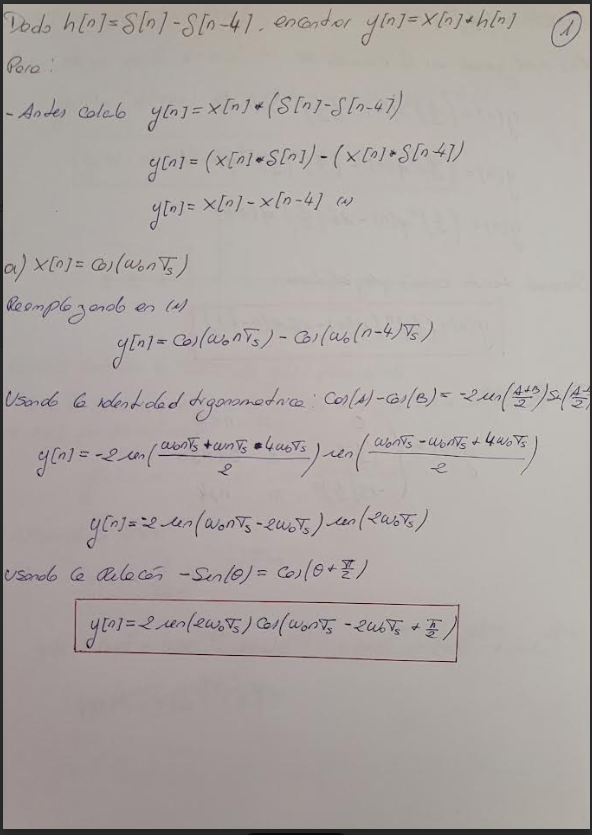

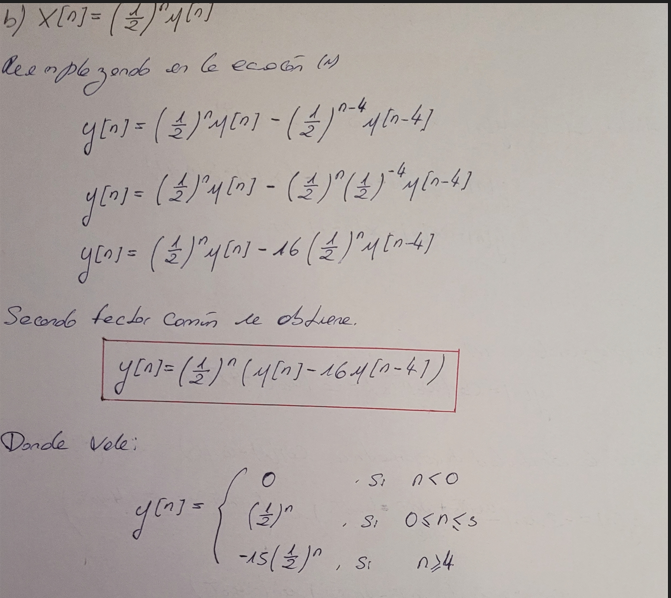

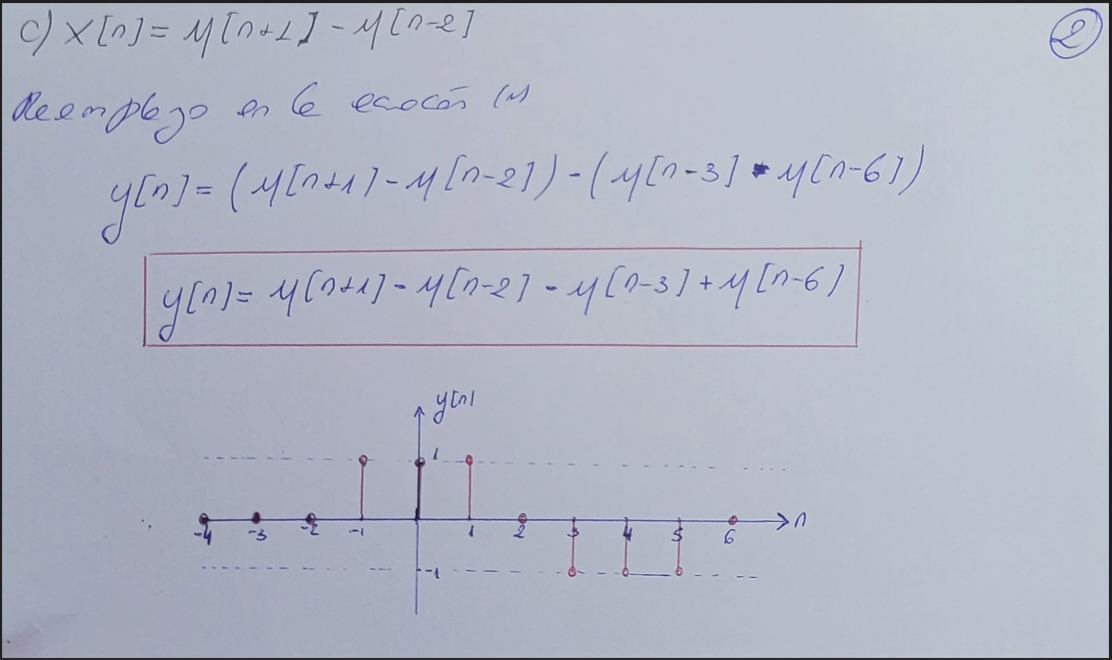

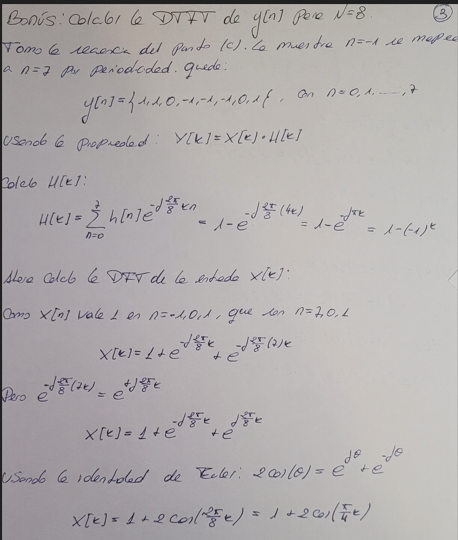

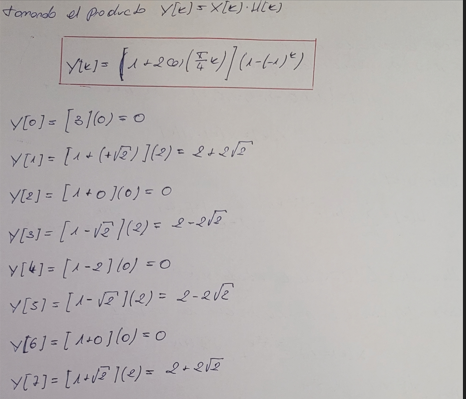

In [7]:
import numpy as np
from scipy.signal import convolve


h = np.array([1, 0, 0, 0, -1])

# c) x[n] = u[n+1] - u[n-2]  
x_c = np.array([1, 1, 1])                 
y_c = convolve(x_c, h)                    
n_c = np.arange(-1, -1 + len(y_c))

print("n =", n_c)
print("y =", y_c)

# BONUS: DFT de y[n] con N = 8
N8 = 8
y8 = np.zeros(N8)
for ni, yi in zip(n_c, y_c):
    y8[ni % N8] += yi              

Y = np.fft.fft(y8, N8)

print("\ny[n] llevado a N=8:", y8)
print("DFT Y[k], N=8:", np.round(Y.real, 4))


n = [-1  0  1  2  3  4  5]
y = [ 1  1  1  0 -1 -1 -1]

y[n] llevado a N=8: [ 1.  1.  0. -1. -1. -1.  0.  1.]
DFT Y[k], N=8: [ 0.      4.8284  0.     -0.8284  0.     -0.8284  0.      4.8284]
